# Classification of Artworks According to Art Movements with Artificial Intelligence

## Step 1: Data Collection (Scraping from wikiart)


In [ ]:
# Downloading the necessary packages
pip install requests tqdm


Active code page: 1252
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Import necessary libraries
import os
import requests
from tqdm import tqdm
import time

# Parameters
STYLE_SLUGS = {
    'impressionism': 'impressionism',
    'baroque': 'baroque',
    'realism': 'realism',
    'romanticism': 'romanticism',
    'expressionism': 'expressionism',
}
IMAGES_PER_STYLE = 3500
SAVE_DIR = 'datasetdataclassification'
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"
}

def fetch_images(style, slug):
    print(f"\n🚀 Scraping style: {style}")
    os.makedirs(f"{SAVE_DIR}/{style}", exist_ok=True)

    all_images = []
    page = 1

    while len(all_images) < IMAGES_PER_STYLE:
        url = f"https://www.wikiart.org/en/paintings-by-style/{slug}?select=featured&json=2&page={page}"
        try:
            response = requests.get(url, headers=HEADERS, timeout=10)
            if response.status_code != 200:
                print(f"⚠️ Error: Status code {response.status_code} on page {page}")
                break

            data = response.json()
            paintings = data.get('Paintings', [])

            if not paintings:
                print("ℹ️ No more paintings found.")
                break

            for painting in paintings:
                if 'image' in painting:
                    all_images.append(painting['image'])

            page += 1
            time.sleep(1)  # polite delay

        except Exception as e:
            print(f"❌ Failed to fetch page {page}: {e}")
            break

    # Trim if too many
    all_images = all_images[:IMAGES_PER_STYLE]
    print(f"✅ Found {len(all_images)} images for {style}")

    # Download
    for idx, img_url in enumerate(tqdm(all_images, desc=f"Downloading {style}")):
        try:
            ext = img_url.split('.')[-1].split('?')[0]
            img_data = requests.get(img_url, headers=HEADERS).content
            with open(f"{SAVE_DIR}/{style}/{style}_{idx}.{ext}", 'wb') as handler:
                handler.write(img_data)
        except Exception as e:
            print(f"❌ Failed to download {img_url}: {e}")

    print(f"✅ Done: {style} - {len(all_images)} images saved.\n")

# Run the scraper
for style, slug in STYLE_SLUGS.items():
    fetch_images(style, slug)



🚀 Scraping style: impressionism
✅ Found 3500 images for impressionism


✅ Done: impressionism - 3500 images saved.


🚀 Scraping style: baroque
✅ Found 3500 images for baroque


✅ Done: baroque - 3500 images saved.


🚀 Scraping style: realism
✅ Found 3500 images for realism


✅ Done: realism - 3500 images saved.


🚀 Scraping style: romanticism
✅ Found 3500 images for romanticism


✅ Done: romanticism - 3500 images saved.


🚀 Scraping style: expressionism
✅ Found 3500 images for expressionism


❌ Failed to download https://uploads2.wikiart.org/00269/images/c-r-w-nevinson/a-tank.jpg: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))


✅ Done: expressionism - 3500 images saved.



# Step 2 : Image Preprocessing Pipeline
- Visualization data
- Loads images
- Removes duplicates
- Standardizes & normalizes
- Augments data
- Creates train/val/test splits


In [ ]:
#  Install Required Packages
!pip install imagehash tqdm torchvision scikit-learn pillow opencv-python numpy

# Verify installations
try:
    import imagehash
    from PIL import Image
    from tqdm import tqdm
    import cv2
    import numpy as np
    print("All packages installed successfully!")
except ImportError as e:
    print(f"Error importing packages: {e}")


Active code page: 1252



[notice] A new release of pip is available: 24.3.1 -> 25.1
[notice] To update, run: python.exe -m pip install --upgrade pip


All packages installed successfully!


#### Imports and Configuration

In [ ]:
#  Imports and Configuration
import os
from torchvision import transforms
from sklearn.model_selection import train_test_split
from collections import Counter
import logging
import os
from collections import Counter
from PIL import Image
import numpy as np
import random
from PIL import Image
import matplotlib.pyplot as plt
from collections import defaultdict


config = {
    'input_dir': 'datasetdataclassification',
    'output_dir': 'processeddataset_classification2',
    'image_size': (224, 224),
    'augmentation_factor': 2,
    'test_size': 0.2,
    'val_size': 0.25,
    'batch_size': 1000
}

# Setup logging
logging.basicConfig(level=logging.INFO,
                   format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)
os.makedirs(config['output_dir'], exist_ok=True)


## - Visualization data before cleaning


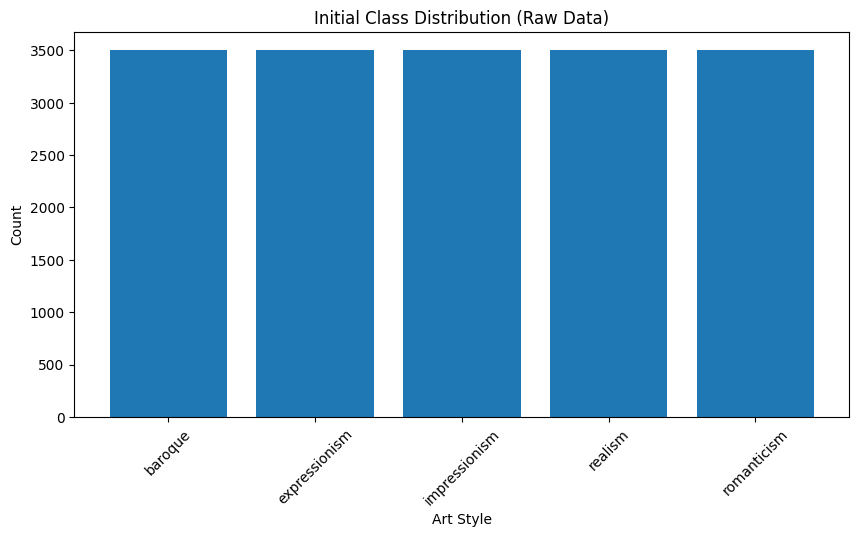


Sample images from each style:


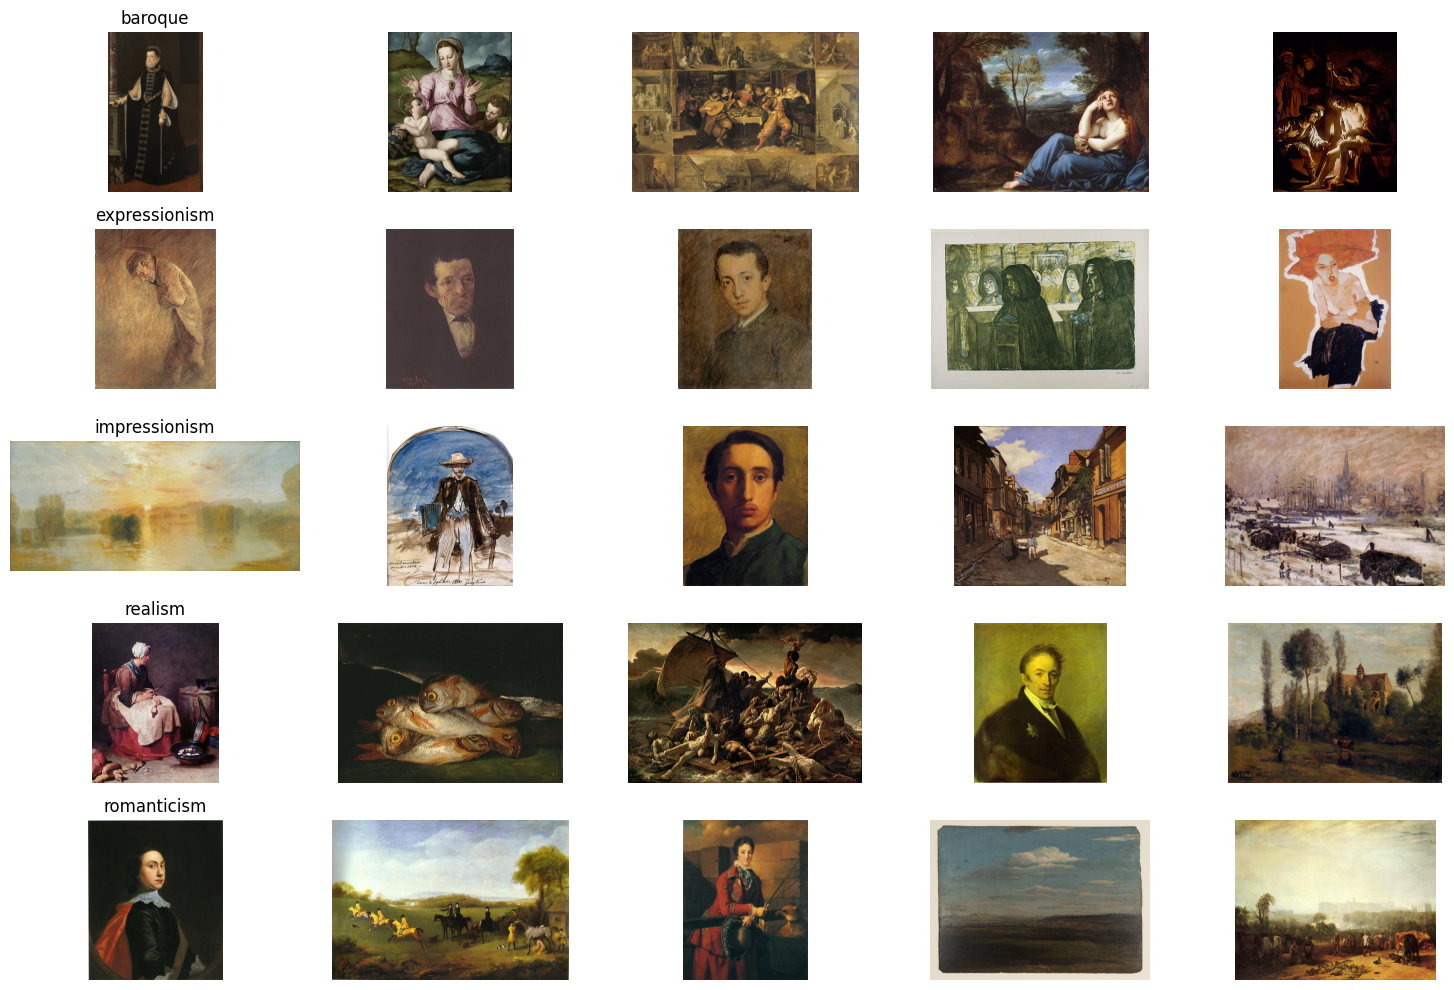

In [ ]:

# Visualization of raw data
def display_sample_images(images_per_style=5):
    plt.figure(figsize=(15, 10))
    for i, style in enumerate(os.listdir(config['input_dir'])):
        style_dir = os.path.join(config['input_dir'], style)
        if os.path.isdir(style_dir):
            # Get first few images from each style
            images = [f for f in os.listdir(style_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:images_per_style]

            for j, img_name in enumerate(images):
                img_path = os.path.join(style_dir, img_name)
                try:
                    img = Image.open(img_path)
                    plt.subplot(len(os.listdir(config['input_dir'])), images_per_style, i*images_per_style + j + 1)
                    plt.imshow(img)
                    plt.title(style if j == 0 else "")
                    plt.axis('off')
                except:
                    continue
    plt.tight_layout()
    plt.show()

# Display class distribution (raw data)
initial_images = []
for style in os.listdir(config['input_dir']):
    style_dir = os.path.join(config['input_dir'], style)
    if os.path.isdir(style_dir):
        for filename in os.listdir(style_dir):
            if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                initial_images.append({'style': style, 'filepath': os.path.join(style_dir, filename)})

# Plot class distribution
styles = [img['style'] for img in initial_images]
plt.figure(figsize=(10, 5))
plt.bar(Counter(styles).keys(), Counter(styles).values())
plt.title("Initial Class Distribution (Raw Data)")
plt.xlabel("Art Style")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

# Display sample images
print("\nSample images from each style:")
display_sample_images()


#### - Loads images


In [ ]:
#  Image Loading (Generator)
def load_images():
    """Yield images one at a time for memory efficiency"""
    for style in os.listdir(config['input_dir']):
        style_dir = os.path.join(config['input_dir'], style)
        if not os.path.isdir(style_dir):
            continue

        for filename in os.listdir(style_dir):
            if not filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue

            filepath = os.path.join(style_dir, filename)
            if is_valid_image(filepath):
                yield {
                    'filepath': filepath,
                    'style': style,
                    'filename': f"{style}_{filename}"
                }


#### -  Image Validation

In [ ]:
#  Image Validation
def is_valid_image(filepath):
    """Check if image is not corrupted"""
    try:
        with Image.open(filepath) as img:
            img.verify()
            return img.mode in ('RGB', 'L') and min(img.size) >= 100
    except Exception as e:
        logger.warning(f"Invalid image {filepath}: {str(e)}")
        return False


#### - Removes duplicates


In [ ]:
#  Deduplication
def phash(img):
    """Perceptual hash using imagehash"""
    return str(imagehash.phash(img))

def remove_duplicates(images):
    """Remove duplicates using perceptual hashing"""
    unique_images = []
    hashes = set()

    for img_info in tqdm(images, desc="Deduplicating"):
        try:
            with Image.open(img_info['filepath']) as img:
                img_hash = phash(img)
                if img_hash not in hashes:
                    hashes.add(img_hash)
                    unique_images.append(img_info)
        except Exception as e:
            logger.warning(f"Skipping {img_info['filepath']}: {str(e)}")

    return unique_images


#### - Standardizes & normalizes


In [ ]:
 # Cell 6: Standardization
def process_image(img_info):
    """Resize, normalize and save a single image"""
    try:
        with Image.open(img_info['filepath']) as img:
            # Convert to RGB if needed
            if img.mode != 'RGB':
                img = img.convert('RGB')

            # Resize and normalize
            img = img.resize(config['image_size'])
            img_array = np.array(img) / 255.0

            # Save processed image
            output_style_dir = os.path.join(config['output_dir'], img_info['style'])
            os.makedirs(output_style_dir, exist_ok=True)
            output_path = os.path.join(output_style_dir, img_info['filename'])

            Image.fromarray((img_array * 255).astype(np.uint8)).save(output_path)
            return True
    except Exception as e:
        logger.error(f"Error processing {img_info['filepath']}: {str(e)}")
        return False


#### - Augments data


In [ ]:
#  Augmentation
def augment_image(img_info, augmenter):
    """Generate augmented versions"""
    augmented = []
    try:
        with Image.open(img_info['filepath']) as img:
            for i in range(config['augmentation_factor']):
                aug_img = augmenter(img)
                base_name = os.path.splitext(img_info['filename'])[0]
                aug_path = os.path.join(config['output_dir'], img_info['style'], f"{base_name}_aug{i}.jpg")
                aug_img.save(aug_path)
                augmented.append({
                    'filepath': aug_path,
                    'style': img_info['style'],
                    'filename': f"{base_name}_aug{i}.jpg"
                })
    except Exception as e:
        logger.error(f"Error augmenting {img_info['filepath']}: {str(e)}")
    return augmented



#### - Creates train/val/test splits


In [ ]:
#  Main Pipeline
def run_pipeline():
    # 1. Load images
    logger.info("Loading images...")
    images = list(load_images())
    logger.info(f"Initial class distribution: {Counter([img['style'] for img in images])}")

    # 2. Remove duplicates
    logger.info("Removing duplicates...")
    unique_images = remove_duplicates(images)
    logger.info(f"Unique images after deduplication: {len(unique_images)}")

    # 3. Standardize images
    logger.info("Standardizing images...")
    processed_images = []
    for img_info in tqdm(unique_images, desc="Processing"):
        if process_image(img_info):
            processed_images.append(img_info)

    # 4. Augment data
    logger.info("Augmenting dataset...")
    augmenter = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2)
    ])

    final_images = []
    for img_info in tqdm(processed_images, desc="Augmenting"):
        final_images.append(img_info)
        final_images.extend(augment_image(img_info, augmenter))

    # 5. Create splits
    logger.info("Creating splits...")
    train, test = train_test_split(final_images, test_size=config['test_size'], random_state=42)
    train, val = train_test_split(train, test_size=config['val_size'], random_state=42)

    # Save split information
    for name, split in [('train', train), ('val', val), ('test', test)]:
        with open(os.path.join(config['output_dir'], f'{name}_files.txt'), 'w') as f:
            for img in split:
                f.write(f"{img['filepath']}\n")

    logger.info(f"""
    Pipeline complete!
    Final dataset size: {len(final_images)} images
    Train: {len(train)} images
    Val: {len(val)} images
    Test: {len(test)} images
    Output directory: {config['output_dir']}
    """)

# %%
#  Execute Pipeline
if __name__ == "__main__":
    run_pipeline()

2025-04-26 19:30:18,061 - INFO - Loading images...
2025-04-26 19:30:53,085 - INFO - Initial class distribution: Counter({'expressionism': 3492, 'impressionism': 3491, 'romanticism': 3488, 'realism': 3487, 'baroque': 3479})
2025-04-26 19:30:53,086 - INFO - Removing duplicates...
Deduplicating: 100%|█████████████████████████████████████████████████████████████| 17437/17437 [09:35<00:00, 30.27it/s]
2025-04-26 19:40:29,114 - INFO - Unique images after deduplication: 17350
2025-04-26 19:40:29,115 - INFO - Standardizing images...
Processing: 100%|████████████████████████████████████████████████████████████████| 17350/17350 [14:41<00:00, 19.68it/s]
2025-04-26 19:55:10,765 - INFO - Augmenting dataset...
Augmenting: 100%|██████████████████████████████████████████████████████████████| 17350/17350 [1:24:23<00:00,  3.43it/s]
2025-04-26 21:19:34,745 - INFO - Creating splits...
2025-04-26 21:19:35,381 - INFO - 
    Pipeline complete!
    Final dataset size: 52050 images
    Train: 31230 images
    V

## - Visualization data after cleaning


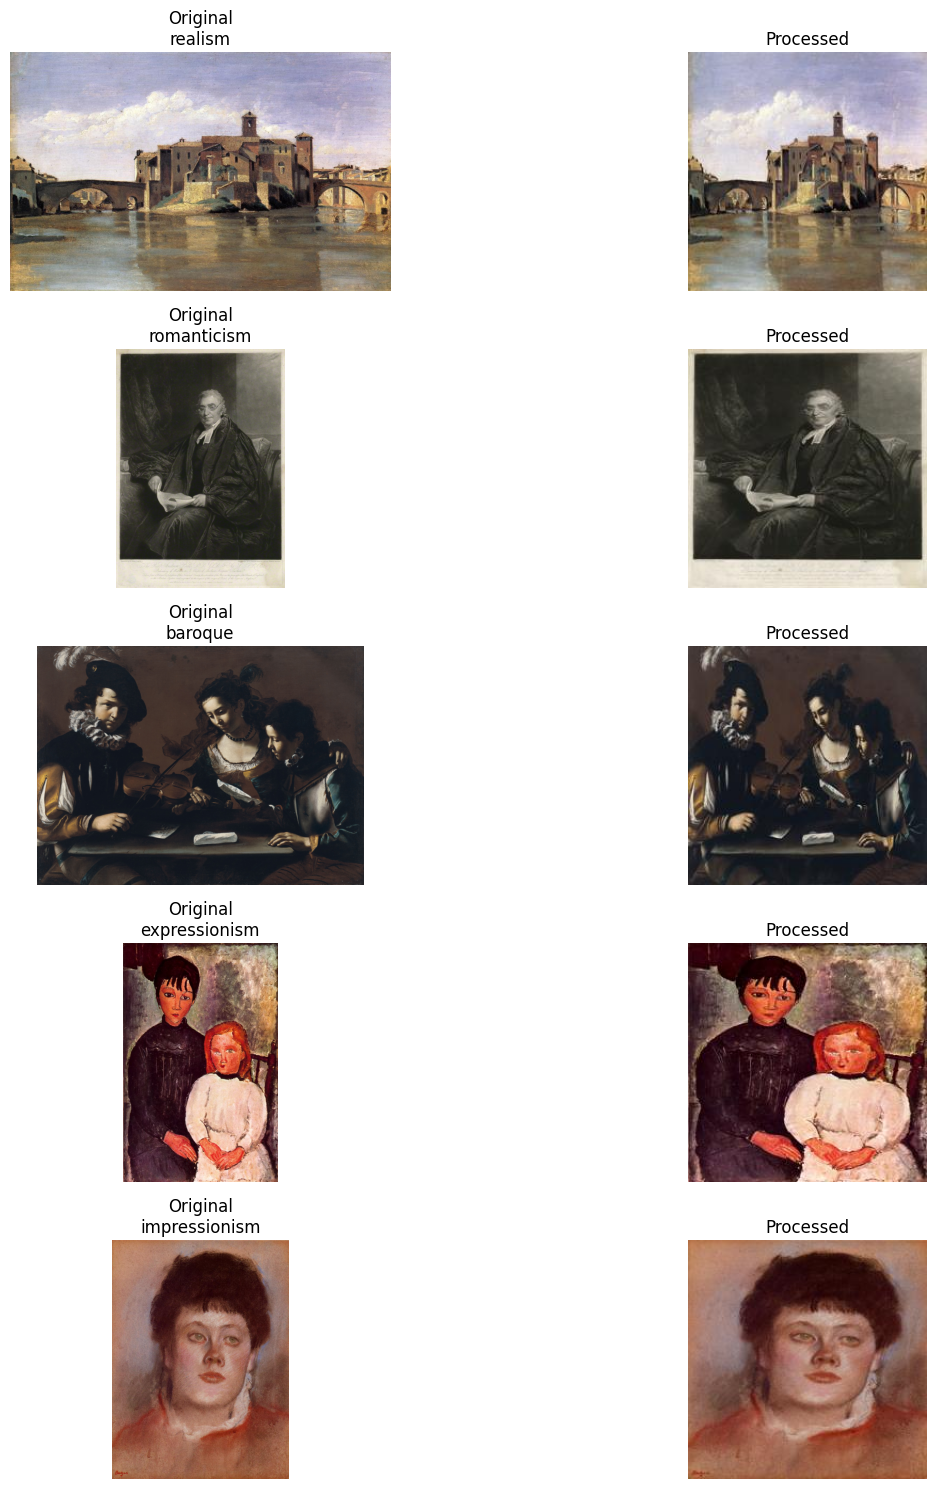

In [ ]:

# --- Load images grouped by style ---
input_dir = config['input_dir']
output_dir = config['output_dir']
styles = os.listdir(input_dir)

style_images = defaultdict(list)

for style in styles:
    style_path = os.path.join(input_dir, style)
    if os.path.isdir(style_path):
        for filename in os.listdir(style_path):
            if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                style_images[style].append({
                    'filepath': os.path.join(style_path, filename),
                    'style': style,
                    'filename': filename
                })

# --- Select one random image per style ---
selected_images = []
for style, images in style_images.items():
    if images:  # Ensure the style has at least one image
        selected_images.append(random.choice(images))

# Shuffle to randomize order (optional)
random.shuffle(selected_images)

# --- Plot original vs processed (one per style) ---
num_styles = len(selected_images)
plt.figure(figsize=(15, 3 * num_styles))  # Adjust height dynamically

for i, img_info in enumerate(selected_images):
    # --- Original Image ---
    orig_img = Image.open(img_info['filepath'])
    plt.subplot(num_styles, 2, 2 * i + 1)  # Left column (original)
    plt.imshow(orig_img)
    plt.title(f"Original\n{img_info['style']}")
    plt.axis('off')

    # --- Processed Image ---
    processed_path = os.path.join(
        output_dir,
        img_info['style'],
        f"{img_info['style']}_{img_info['filename']}"  # Adjust if naming differs
    )

    if os.path.exists(processed_path):
        processed_img = Image.open(processed_path)
        plt.subplot(num_styles, 2, 2 * i + 2)  # Right column (processed)
        plt.imshow(processed_img)
        plt.title("Processed")
        plt.axis('off')
    else:
        print(f"Warning: Processed image not found at {processed_path}")
        plt.subplot(num_styles, 2, 2 * i + 2)
        plt.text(0.5, 0.5, "Not Found", ha='center', va='center')
        plt.axis('off')

plt.tight_layout()
plt.show()

###  Dataset Split Visualization


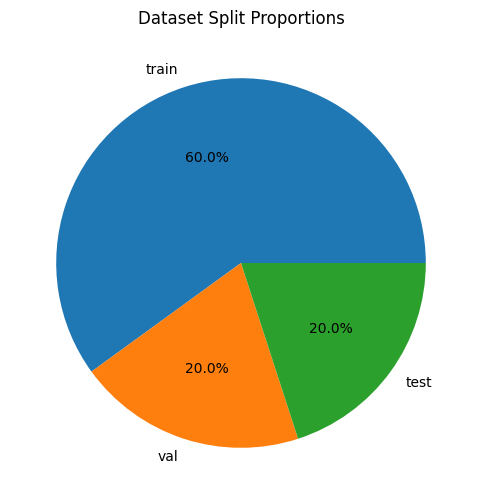

In [ ]:
# Cell 14: Dataset Split Visualization
split_counts = {}
for split in ['train', 'val', 'test']:
    split_file = os.path.join(config['output_dir'], f'{split}_files.txt')
    if os.path.exists(split_file):
        with open(split_file, 'r') as f:
            split_counts[split] = len(f.readlines())

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(split_counts.values(), labels=split_counts.keys(), autopct='%1.1f%%')
plt.title("Dataset Split Proportions")
plt.show()

### final dataset size after increasing it

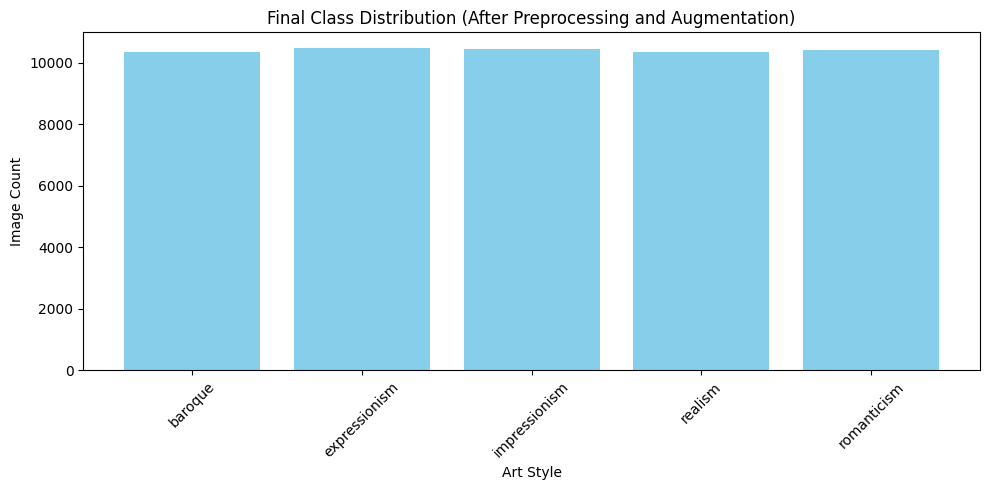

In [ ]:


# Path to the processed dataset
processed_dir = "processeddataset_classification2"

# Count images in each class
class_counts = {}
for style in os.listdir(processed_dir):
    style_path = os.path.join(processed_dir, style)
    if os.path.isdir(style_path):
        num_images = len([
            file for file in os.listdir(style_path)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ])
        class_counts[style] = num_images

# Plotting the final class distribution
plt.figure(figsize=(10, 5))
plt.bar(class_counts.keys(), class_counts.values(), color='skyblue')
plt.title("Final Class Distribution (After Preprocessing and Augmentation)")
plt.xlabel("Art Style")
plt.ylabel("Image Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
